# New Zealand Electricity Demand Analysis

**Period:** 1–31 October 2026  
**Data source:** Electricity Authority New Zealand — Electricity Market Information (EMI)  
**Tools:** Python, Pandas, Matplotlib

## Project Overview

I'm a first-year student studying Computer Science and Mathematics at Victoria University of Wellington. I'm interested in quantitative analysis and wanted to explore how the skills I'm learning at university can be applied to real-world data.

For this project, I used publicly available data from New Zealand's Electricity Authority to explore electricity demand patterns during October 2026.

My analysis focuses on four questions:

1. How did national electricity demand change throughout the month?
2. What times of day had the highest and lowest average demand?
3. How did electricity demand differ between weekdays and weekends?
4. How was electricity demand distributed across New Zealand's five electricity regions?

The project uses Python for data processing, descriptive statistics and visualisation.

1. Data Loading and Preparation

In [17]:

import pandas as pd

# Read the official electricity demand data
df = pd.read_csv(
    "Demand_trends_20261112002832.csv",
    skiprows=11
)

# Show the first five rows
print(df.head())

# Show the number of rows and columns
print("Dataset shape:", df.shape)


          Period start           Period end Region ID                Region  \
0  01/10/2026 00:00:00  01/10/2026 00:30:00       UNI    Upper North Island   
1  01/10/2026 00:00:00  01/10/2026 00:30:00       CNI  Central North Island   
2  01/10/2026 00:00:00  01/10/2026 00:30:00       LNI    Lower North Island   
3  01/10/2026 00:00:00  01/10/2026 00:30:00       USI    Upper South Island   
4  01/10/2026 00:00:00  01/10/2026 00:30:00       LSI    Lower South Island   

   Demand (GWh)  Demand ($)  
0         0.581     5760.31  
1         0.404     3805.13  
2         0.272     2278.24  
3         0.314     2297.28  
4         0.534     3436.08  
Dataset shape: (7440, 6)


2. National Electricity Demand Summary

In [18]:

# Calculate total electricity demand
total_demand = df["Demand (GWh)"].sum()

print("Total demand:", total_demand, "GWh")


Total demand: 3508.224 GWh


In [19]:

# Convert the date column into datetime format
df["Period start"] = pd.to_datetime(
    df["Period start"],
    dayfirst=True
)

# Group data by time and sum regional demand
national_demand = df.groupby(
    "Period start"
)["Demand (GWh)"].sum()

# Display the first five records
print(national_demand.head())


Period start
2026-10-01 00:00:00    2.105
2026-10-01 00:30:00    2.035
2026-10-01 01:00:00    1.993
2026-10-01 01:30:00    1.940
2026-10-01 02:00:00    1.908
Name: Demand (GWh), dtype: float64


In [20]:

# Calculate average national demand
average_demand = national_demand.mean()

# Find maximum and minimum demand
max_demand = national_demand.max()
min_demand = national_demand.min()

# Find when they occurred
max_time = national_demand.idxmax()
min_time = national_demand.idxmin()

print("Average:", round(average_demand, 3), "GWh")
print("Maximum:", max_demand, "GWh")
print("Maximum time:", max_time)
print("Minimum:", round(min_demand, 3), "GWh")
print("Minimum time:", min_time)


Average: 2.358 GWh
Maximum: 3.015 GWh
Maximum time: 2026-10-16 08:00:00
Minimum: 1.707 GWh
Minimum time: 2026-10-12 03:00:00


3. National Demand Trends

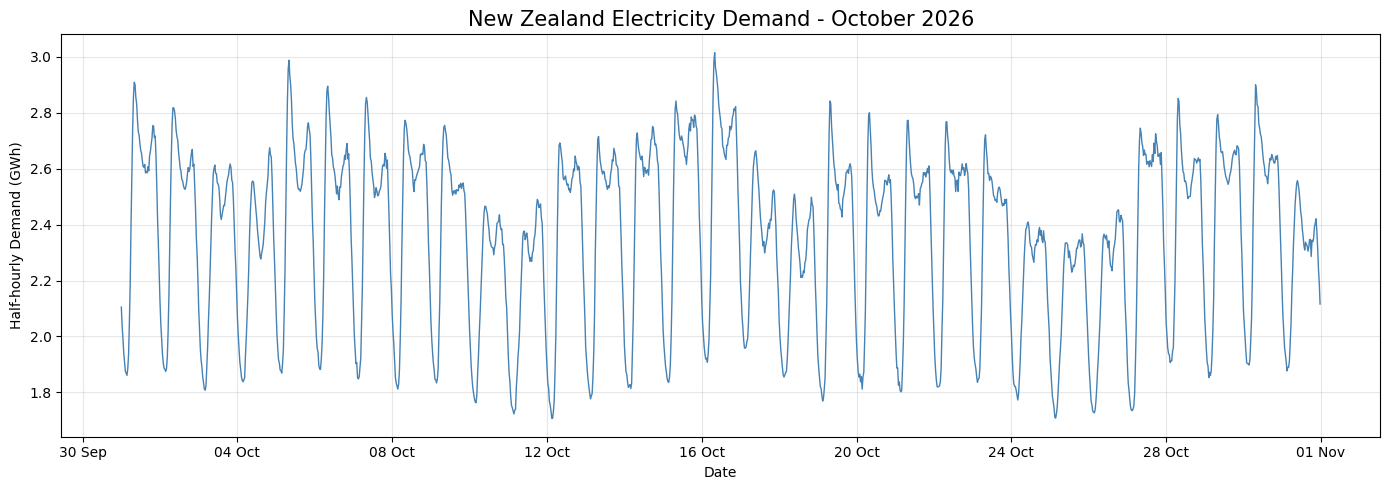

In [21]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Create a chart
plt.figure(figsize=(14, 5))

# Plot national electricity demand
plt.plot(
    national_demand.index,
    national_demand.values,
    color="steelblue",
    linewidth=1
)

# Add chart title and labels
plt.title(
    "New Zealand Electricity Demand - October 2026",
    fontsize=15
)

plt.xlabel("Date")
plt.ylabel("Half-hourly Demand (GWh)")

# Format the date axis
plt.gca().xaxis.set_major_locator(
    mdates.DayLocator(interval=4)
)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

# Add grid lines
plt.grid(alpha=0.3)

# Improve layout
plt.tight_layout()

plt.savefig(
    "NZ_Electricity_Demand_Oct2026.png",
    dpi=300,
    bbox_inches="tight"
)
# Display chart
plt.show()


In [22]:

# Create a copy of the national demand data
hourly_data = national_demand.reset_index()

# Extract the time of day
hourly_data["Time"] = hourly_data["Period start"].dt.strftime("%H:%M")

# Calculate average demand for each half-hour
average_by_time = hourly_data.groupby("Time")["Demand (GWh)"].mean()

# Display the first five results
print(average_by_time.head())

# Find the peak and lowest demand times
peak_time = average_by_time.idxmax()
peak_demand = average_by_time.max()

lowest_time = average_by_time.idxmin()
lowest_demand = average_by_time.min()

print("Peak time:", peak_time)
print("Peak average demand:", round(peak_demand, 3), "GWh")
print("Lowest time:", lowest_time)
print("Lowest average demand:", round(lowest_demand, 3), "GWh")


Time
00:00    2.036000
00:30    1.971968
01:00    1.924258
01:30    1.885258
02:00    1.861903
Name: Demand (GWh), dtype: float64
Peak time: 08:00
Peak average demand: 2.666 GWh
Lowest time: 03:30
Lowest average demand: 1.826 GWh


4. Average Demand by Time of Day

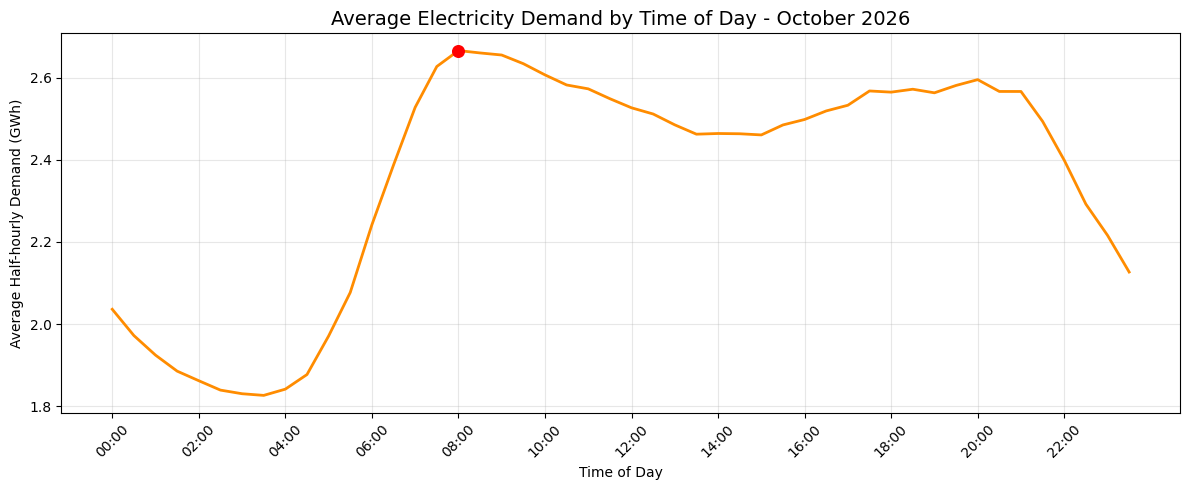

In [23]:

import matplotlib.pyplot as plt

# Create a figure
plt.figure(figsize=(12, 5))

# Plot average demand by time of day
plt.plot(
    average_by_time.index,
    average_by_time.values,
    color="darkorange",
    linewidth=2
)

# Highlight the peak demand
plt.scatter(
    peak_time,
    peak_demand,
    color="red",
    s=70,
    zorder=5
)

# Add title and labels
plt.title(
    "Average Electricity Demand by Time of Day - October 2026",
    fontsize=14
)

plt.xlabel("Time of Day")
plt.ylabel("Average Half-hourly Demand (GWh)")

# Show one label every two hours
plt.xticks(
    range(0, 48, 4),
    average_by_time.index[::4],
    rotation=45
)

plt.grid(alpha=0.3)
plt.tight_layout()

# Save the chart
plt.savefig(
    "NZ_Average_Demand_By_Time.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [24]:

# Convert national demand into a DataFrame
comparison_data = national_demand.reset_index()

# Get the day of the week
comparison_data["Day of Week"] = comparison_data["Period start"].dt.dayofweek

# Classify each record as Weekday or Weekend
comparison_data["Day Type"] = comparison_data["Day of Week"].apply(
    lambda day: "Weekday" if day < 5 else "Weekend"
)

# Calculate average demand for each group
weekday_weekend = comparison_data.groupby(
    "Day Type"
)["Demand (GWh)"].mean()

print(weekday_weekend)


Day Type
Weekday    2.407868
Weekend    2.234988
Name: Demand (GWh), dtype: float64


In [25]:

# Get the average demand for each group
weekday_avg = weekday_weekend["Weekday"]
weekend_avg = weekday_weekend["Weekend"]

# Calculate the difference
difference = weekday_avg - weekend_avg

# Calculate percentage difference
percentage = (difference / weekday_avg) * 100

print("Weekday average:", round(weekday_avg, 3), "GWh")
print("Weekend average:", round(weekend_avg, 3), "GWh")
print("Difference:", round(difference, 3), "GWh")
print("Percentage difference:", round(percentage, 2), "%")


Weekday average: 2.408 GWh
Weekend average: 2.235 GWh
Difference: 0.173 GWh
Percentage difference: 7.18 %


5. Weekday vs Weekend Comparison

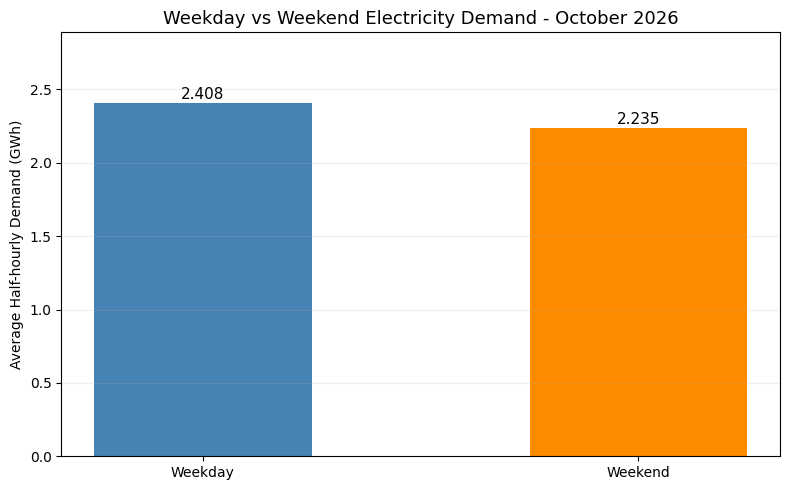

In [26]:

import matplotlib.pyplot as plt

# Set the order of categories
categories = ["Weekday", "Weekend"]
values = [weekday_avg, weekend_avg]

# Create a figure
plt.figure(figsize=(8, 5))

# Create a bar chart
bars = plt.bar(
    categories,
    values,
    color=["steelblue", "darkorange"],
    width=0.5
)

# Add values above the bars
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.03,
        f"{height:.3f}",
        ha="center",
        fontsize=11
    )

# Add title and labels
plt.title(
    "Weekday vs Weekend Electricity Demand - October 2026",
    fontsize=13
)

plt.ylabel("Average Half-hourly Demand (GWh)")
plt.ylim(0, max(values) * 1.2)

# Add horizontal grid lines
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()

# Save the chart
plt.savefig(
    "NZ_Weekday_vs_Weekend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [27]:

# Calculate total demand for each region
regional_demand = df.groupby(
    "Region"
)["Demand (GWh)"].sum()

# Sort regions from highest to lowest demand
regional_demand = regional_demand.sort_values(
    ascending=False
)

# Display the results
print(regional_demand)

# Calculate each region's percentage of national demand
regional_share = (
    regional_demand / regional_demand.sum()
) * 100

print("\nRegional shares (%):")
print(regional_share.round(2))


Region
Upper North Island      967.056
Lower South Island      825.589
Central North Island    683.701
Upper South Island      518.577
Lower North Island      513.301
Name: Demand (GWh), dtype: float64

Regional shares (%):
Region
Upper North Island      27.57
Lower South Island      23.53
Central North Island    19.49
Upper South Island      14.78
Lower North Island      14.63
Name: Demand (GWh), dtype: float64


6. Regional Demand Analysis

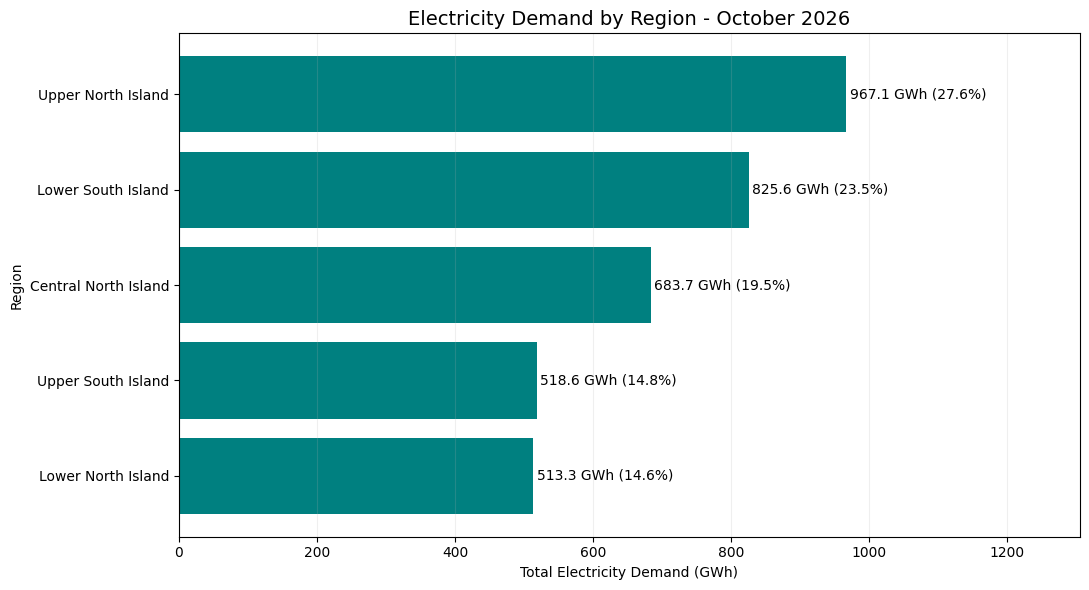

In [28]:

import matplotlib.pyplot as plt

# Create a figure
plt.figure(figsize=(11, 6))

# Create horizontal bars
bars = plt.barh(
    regional_demand.index,
    regional_demand.values,
    color="teal"
)

# Put the largest region at the top
plt.gca().invert_yaxis()

# Add values and percentages beside each bar
for bar, share in zip(bars, regional_share.values):
    width = bar.get_width()

    plt.text(
        width + 5,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f} GWh ({share:.1f}%)",
        va="center",
        fontsize=10
    )

# Add title and labels
plt.title(
    "Electricity Demand by Region - October 2026",
    fontsize=14
)

plt.xlabel("Total Electricity Demand (GWh)")
plt.ylabel("Region")

# Leave space for labels
plt.xlim(0, regional_demand.max() * 1.35)

plt.grid(axis="x", alpha=0.2)
plt.tight_layout()

# Save chart
plt.savefig(
    "NZ_Electricity_Demand_By_Region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


7. Key Findings and Limitations

## 7. Key Findings and Limitations

### Key Findings

- Total electricity demand during October 2026 was **3,508.224 GWh**.
- The average national demand per half-hour was approximately **2.358 GWh**.
- The highest average demand occurred during the **08:00–08:30** period, while the lowest occurred during **03:30–04:00**.
- Average half-hourly demand was **2.408 GWh on weekdays** and **2.235 GWh on weekends**, approximately **7.18% lower on weekends**.
- The **Upper North Island** recorded the highest total demand among the five electricity zones, at **967.056 GWh**.

### Limitations

This analysis covers only October 2026, so it cannot establish annual or seasonal patterns.

Public holidays are included in the weekday category. The analysis also focuses on descriptive statistics and does not establish the causes of changes in electricity demand.

The source reports electricity demand in GWh for each half-hourly trading period. These values represent energy over a period rather than instantaneous power.

### What I Learned

This project helped me practise using Python and Pandas to clean, group and analyse real-world data. I also learned how to create visualisations and communicate quantitative findings clearly.

I would like to develop this project further by exploring seasonal patterns and the relationship between electricity demand and wholesale prices.